## Hand Landmarks Model (Media Pipe)

In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
from handspell.model_landmarks import create_landmarker, find_images, read_rgb, get_features, extract_features


In [2]:
landmarker = create_landmarker(min_hand_detection_confidence=0.1,
                               min_hand_presence_confidence=0.1)

MediaPipe model: ../models/hand_landmarker.task


I0000 00:00:1792501068.467197 6514979 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792501068.485306 6514984 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792501068.498813 6514984 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [3]:
paths, labels = find_images('../data/dataset/D02_original_aslmnist')

In [4]:
paths

[PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A0.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A1.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A2.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A3.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A4.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A5.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A6.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A7.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A8.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A9.jpg'),
 PosixPath('../data/dataset/D02_original_aslmnist/A/B01_orig

In [5]:
type(paths[0])

pathlib.PosixPath

In [6]:
labels

array([ 0,  0,  0, ..., 23, 23, 23], shape=(1680,))

In [7]:
rgb = read_rgb(paths[0])

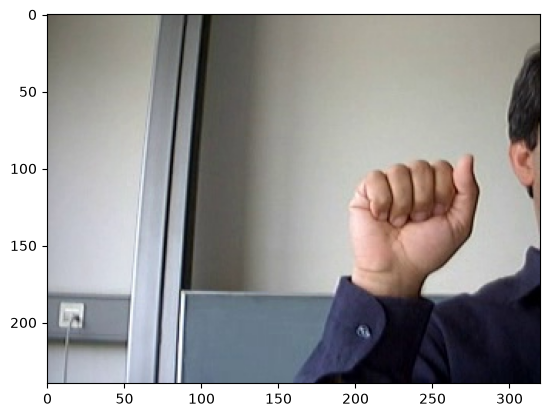

In [8]:
import matplotlib.pyplot as plt
plt.imshow(rgb)

In [9]:
type(landmarker)

mediapipe.tasks.python.vision.hand_landmarker.HandLandmarker

In [10]:
features, landmarks = get_features(rgb, landmarker)

W0000 00:00:1792501112.748535 6514981 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


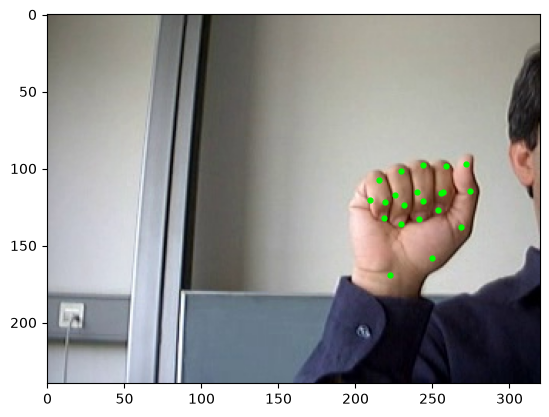

In [11]:
_, ax = plt.subplots(1,1)

ax.imshow(rgb)

if landmarks:
    height, width = rgb.shape[:2]
    ax.scatter(
        [point.x * width for point in landmarks],
        [point.y * height for point in landmarks],
        s=12,
        c="lime",
    )
    status = "detected"
else:
    status = "NO HAND"

In [12]:
features, failures = extract_features(paths)

MediaPipe model: ../models/hand_landmarker.task


W0000 00:00:1792501114.517856 6515690 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792501114.537743 6515695 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/1680 [00:00<?, ?it/s]

In [13]:
features

array([[ 0.        ,  0.        ,  0.        , ..., -0.06812175,
        -0.65596855, -0.24931887],
       [ 0.        ,  0.        ,  0.        , ..., -0.04845177,
        -0.66427636, -0.2509724 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.06770041,
        -0.6667545 , -0.24127516],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.05876412,
        -1.5596192 ,  0.34855425],
       [ 0.        ,  0.        ,  0.        , ..., -0.06551302,
        -1.5673888 ,  0.36658326],
       [ 0.        ,  0.        ,  0.        , ..., -0.08882862,
        -1.590285  ,  0.3357074 ]], shape=(1680, 63), dtype=float32)

In [17]:
import pandas as pd
pd.DataFrame(features).head()

,0,1,2,3,4,5,6,7,8,9,...,53,54,55,56,57,58,59,60,61,62
0,0.0,0.0,0.0,0.479246,-0.185294,-0.107339,0.815667,-0.546880,-0.154431,0.912657,...,-0.201848,-0.132541,-1.080982,-0.344998,-0.061869,-0.829100,-0.308925,-0.068122,-0.655969,-0.249319
1,0.0,0.0,0.0,0.484542,-0.187092,-0.098333,0.820684,-0.545880,-0.141401,0.920790,...,-0.191346,-0.119866,-1.083609,-0.328813,-0.047909,-0.842692,-0.302222,-0.048452,-0.664276,-0.250972
2,0.0,0.0,0.0,0.480062,-0.194399,-0.105532,0.814562,-0.552946,-0.154032,0.911554,...,-0.201652,-0.136472,-1.096654,-0.341467,-0.060777,-0.845491,-0.303110,-0.067700,-0.666754,-0.241275
3,0.0,0.0,0.0,0.440871,-0.207210,-0.113268,0.751925,-0.568707,-0.169356,0.849843,...,-0.220221,-0.161028,-1.086689,-0.373913,-0.078543,-0.827653,-0.333122,-0.080770,-0.652780,-0.266430
4,0.0,0.0,0.0,0.394601,-0.224279,-0.118817,0.660534,-0.597688,-0.176602,0.785034,...,-0.223548,-0.230548,-1.022539,-0.365435,-0.142395,-0.771258,-0.299968,-0.151837,-0.633205,-0.215709


In [19]:
paths[0].name

'B01_original_aslmnist__user_10__A0.jpg'

In [29]:
p = paths[0]

In [24]:
str(p)

'../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A0.jpg'

In [44]:
failures

[]

In [37]:
dataset_labels = []
users = []
# for p in paths:
splits = p.name.split('__')
dataset_labels += [splits[0]]
if len(splits)>2:
    users += [splits[1]]
else:
    users += [""]

In [38]:
splits

['B01_original_aslmnist', 'user_10', 'A0.jpg']

In [39]:
dataset_labels

['B01_original_aslmnist']

In [ ]:
dataset_labels

['B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's',
 't',
 'B',
 '0',
 '1',
 '_',
 'o',
 'r',
 'i',
 'g',
 'i',
 'n',
 'a',
 'l',
 '_',
 'a',
 's',
 'l',
 'm',
 'n',
 'i',
 's'

In [ ]:
features_df = pd.DataFrame(features)

dataset_labels = []
users = []
for p in paths:
    splits = p.name.split('__')
    dataset_labels += [splits[0]]
    if len(splits)>2:
        users += [splits[1]]
    else:
        users += [""]

# Add label
features_df["letter_index"] = labels

# Add Dataset label
features_df["dataset"] = dataset_labels

# Add User/Person
features_df["user"] = users

# Add image path
features_df["image_path"] = [str(p) for p in paths]

features_df

,0,1,2,3,4,5,6,7,8,9,...,57,58,59,60,61,62,letter_index,dataset,user,image_path
0,0.0,0.0,0.0,0.479246,-0.185294,-0.107339,0.815667,-0.546880,-0.154431,0.912657,...,-0.061869,-0.829100,-0.308925,-0.068122,-0.655969,-0.249319,0,B01_original_aslmnist,user_10,../data/dataset/D02_original_aslmnist/A/B01_or...
1,0.0,0.0,0.0,0.484542,-0.187092,-0.098333,0.820684,-0.545880,-0.141401,0.920790,...,-0.047909,-0.842692,-0.302222,-0.048452,-0.664276,-0.250972,0,B01_original_aslmnist,user_10,../data/dataset/D02_original_aslmnist/A/B01_or...
2,0.0,0.0,0.0,0.480062,-0.194399,-0.105532,0.814562,-0.552946,-0.154032,0.911554,...,-0.060777,-0.845491,-0.303110,-0.067700,-0.666754,-0.241275,0,B01_original_aslmnist,user_10,../data/dataset/D02_original_aslmnist/A/B01_or...
3,0.0,0.0,0.0,0.440871,-0.207210,-0.113268,0.751925,-0.568707,-0.169356,0.849843,...,-0.078543,-0.827653,-0.333122,-0.080770,-0.652780,-0.266430,0,B01_original_aslmnist,user_10,../data/dataset/D02_original_aslmnist/A/B01_or...
4,0.0,0.0,0.0,0.394601,-0.224279,-0.118817,0.660534,-0.597688,-0.176602,0.785034,...,-0.142395,-0.771258,-0.299968,-0.151837,-0.633205,-0.215709,0,B01_original_aslmnist,user_10,../data/dataset/D02_original_aslmnist/A/B01_or...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1675,0.0,0.0,0.0,0.521480,-0.199583,-0.247462,0.905948,-0.650248,-0.265680,1.113108,...,-0.127193,-1.375926,0.069287,-0.077663,-1.624982,0.079102,23,B01_original_aslmnist,user_9,../data/dataset/D02_original_aslmnist/Y/B01_or...
1676,0.0,0.0,0.0,0.607215,-0.203150,-0.217864,1.019084,-0.645405,-0.190841,1.242967,...,-0.119596,-1.378583,0.261282,-0.050426,-1.614315,0.277990,23,B01_original_aslmnist,user_9,../data/dataset/D02_original_aslmnist/Y/B01_or...
1677,0.0,0.0,0.0,0.600154,-0.226806,-0.232760,0.993797,-0.656378,-0.209631,1.211326,...,-0.128412,-1.335435,0.323778,-0.058764,-1.559619,0.348554,23,B01_original_aslmnist,user_9,../data/dataset/D02_original_aslmnist/Y/B01_or...
1678,0.0,0.0,0.0,0.614237,-0.231518,-0.214438,1.003356,-0.668061,-0.175606,1.213414,...,-0.147596,-1.337488,0.347605,-0.065513,-1.567389,0.366583,23,B01_original_aslmnist,user_9,../data/dataset/D02_original_aslmnist/Y/B01_or...


In [ ]:
features_df